Raw Data Shape: (401602, 15)

RFM Data Shape: (4372, 12)


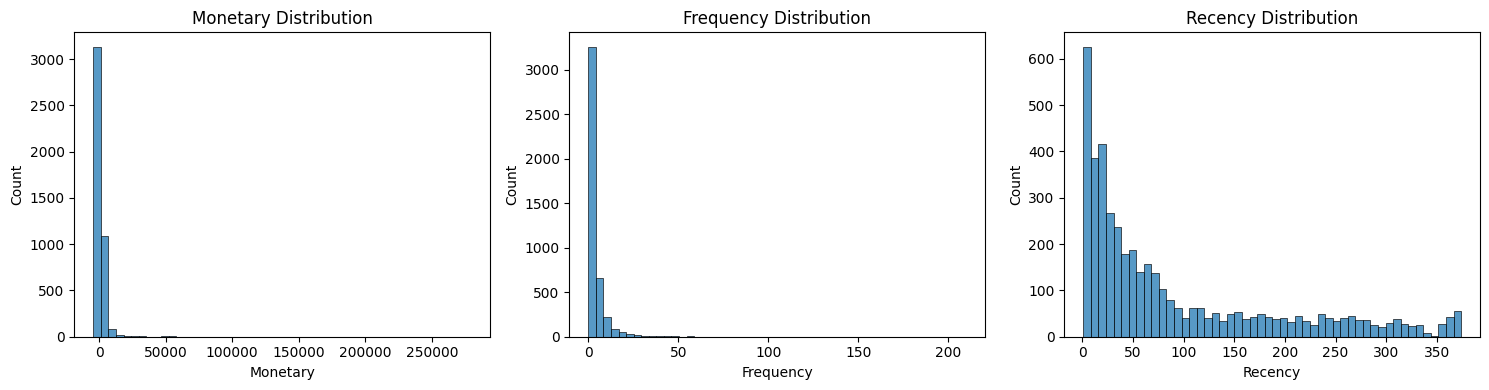

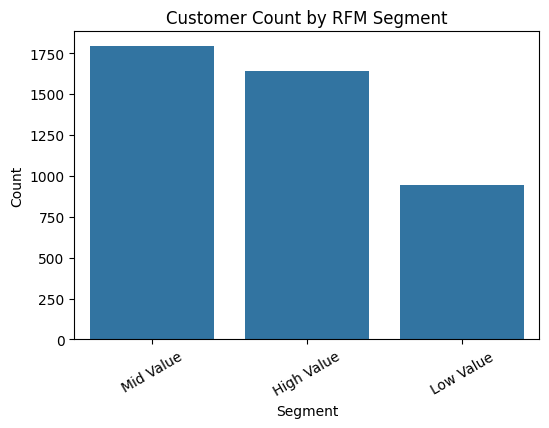

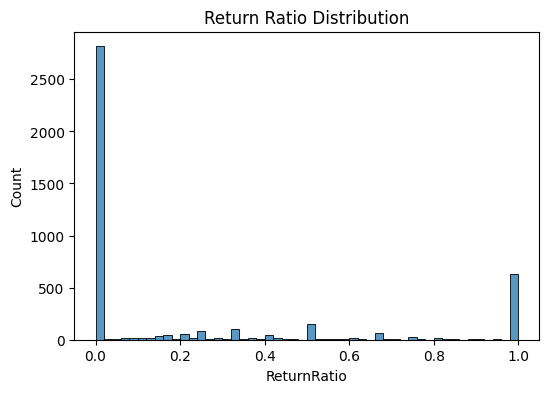

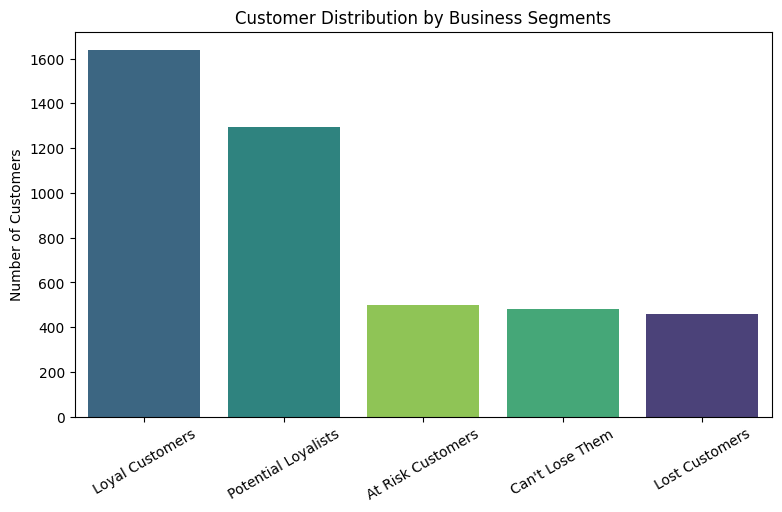

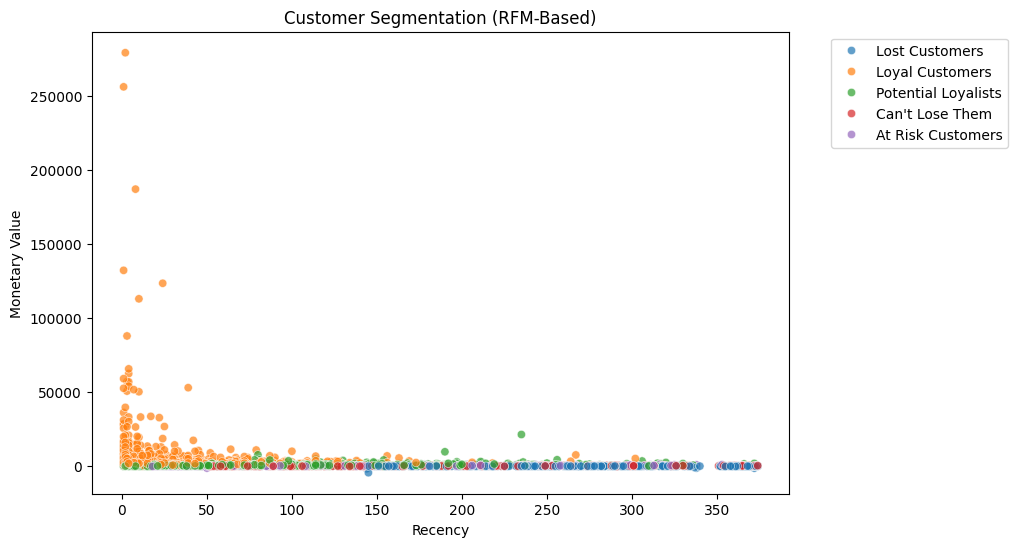


--- Elbow Method ---


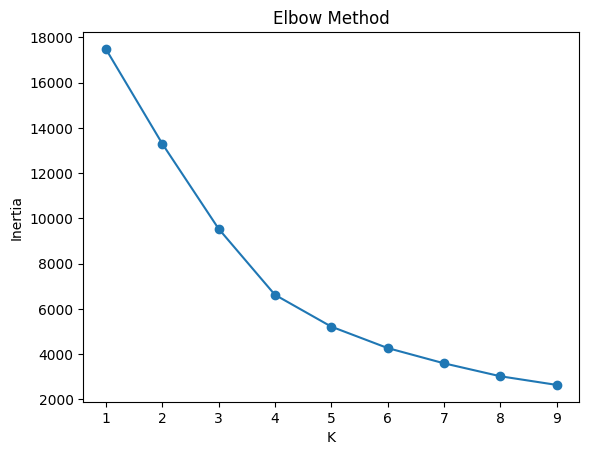


--- Dendrogram ---


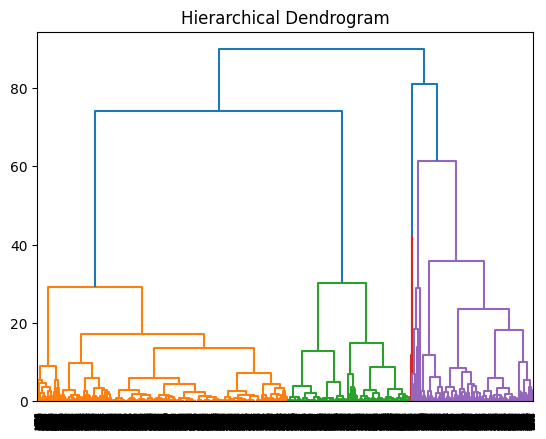


--- Model Tuning ---
KMeans → Best K: 8, Score: 0.5428


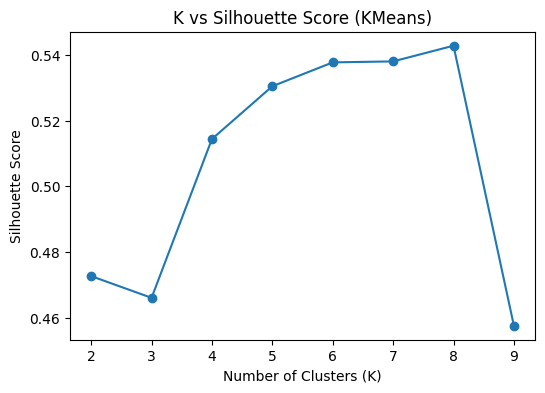

DBSCAN → Score: -1.0000
K=2, Score=0.4686
K=3, Score=0.4654
K=4, Score=0.4653
K=5, Score=0.4922
K=6, Score=0.4926
K=7, Score=0.4942
K=8, Score=0.4378
K=9, Score=0.4477
Hierarchical → Best Score: 0.4942


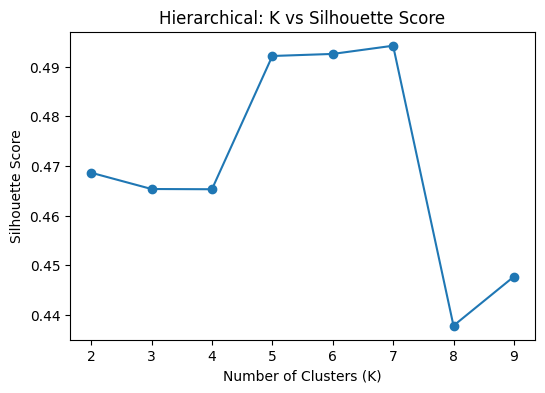


--- Silhouette Score Comparison ---


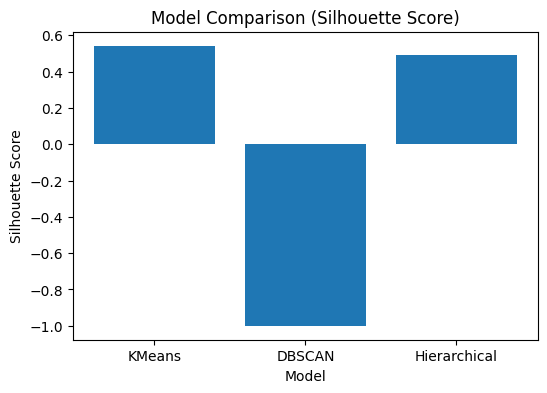


Cluster Summary:
            Recency   Frequency       Monetary  ReturnRatio  CustomerID
Cluster                                                                
0        254.652275    1.411902     367.773116     0.007637         857
1         34.229822    4.626539    1955.567990     0.838842         731
2         12.788288   19.292793    8365.296171     0.328390         222
3          3.666667   60.000000  241083.226667     0.135083           3
4         46.120259    3.244397    1094.130372     0.038725        2320
5          6.900000   56.800000   54182.729000     0.544393          20
6        226.645161    1.875576     783.497931     0.917972         217
7          1.000000  205.500000   80432.145000     0.609524           2


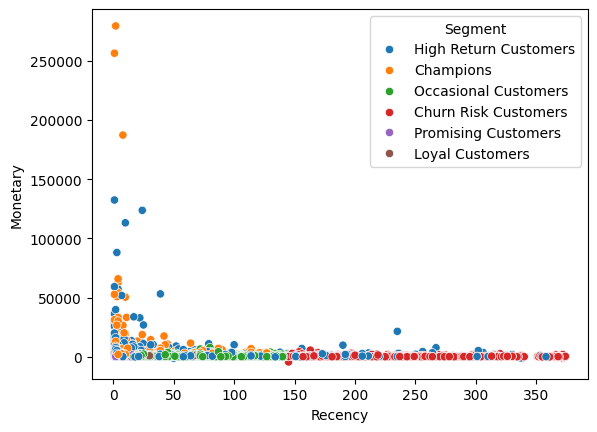


Best Model Selected: KMeans

Model Comparison:
          Model  Silhouette Score
0        KMeans          0.542798
1        DBSCAN         -1.000000
2  Hierarchical          0.494241

Final Segments:
Segment
Occasional Customers     1468
High Return Customers    1090
Churn Risk Customers      884
Promising Customers       414
Champions                 403
Loyal Customers           113
Name: count, dtype: int64

 Cluster summary saved: data/cluster_summary.csv

 File saved: data/rfm_final.csv


In [2]:
import pandas as pd

# The modules
from src.rfm_analysis import run_rfm_pipeline
from src.clustering import run_pipeline
from src.visualization import (
    plot_rfm_distributions,
    plot_rfm_segments,
    plot_return_behavior,
    plot_3d_clusters,
    plot_detailed_segments,
    plot_rfm_segment_scatter
)
# Load dataset
df = pd.read_csv(r"C:\Users\hp\Downloads\BIA\E-commerce_Customer_Segmentation_and_Prediction\data\known.csv")  

print("Raw Data Shape:", df.shape)
df.head()
# Generate RFM table
rfm_df = run_rfm_pipeline(df)

print("\nRFM Data Shape:", rfm_df.shape)
rfm_df.head()
# Basic analysis plots
plot_rfm_distributions(rfm_df)
plot_rfm_segments(rfm_df)
plot_return_behavior(rfm_df)
plot_detailed_segments(rfm_df)
plot_rfm_segment_scatter(rfm_df)
rfm_clustered, scores, best_model, summary = run_pipeline(
    rfm_df,
    show_plots=True
)
print("\nBest Model Selected:", best_model)

print("\nModel Comparison:")
print(scores)

print("\nFinal Segments:")
print(rfm_clustered['Segment'].value_counts())
plot_3d_clusters(rfm_clustered)
rfm_clustered.to_csv("data/rfm_final.csv", index=False)
summary.to_csv("data/cluster_summary.csv")

print("\n Cluster summary saved: data/cluster_summary.csv")

print("\n File saved: data/rfm_final.csv")